# La CNN-Transformer con otras semillas

El sistema en producción se entrenó con la semilla 42. Una sola semilla no dice si el resultado es lo normal o si fue suerte: con otra, la red empieza con otros pesos, ve los trozos de la noche en otro orden y recibe otros canales sorteados, y el XGBoost enmascara otras épocas. En esta carpeta se entrena **el sistema completo otra vez con las semillas 1, 2, 3 y 4** y se compara con el de la 42.

Todo lo demás queda igual: la partición (`particiones.json`), los hiperparámetros, el preprocesamiento y las 100 columnas del XGBoost. El bootstrap de la evaluación también usa siempre la semilla 42, para que las 5 semillas se midan con las mismas remuestras.

Los notebooks van en orden:
1. `1_entrenamiento_red.ipynb`: la CNN-Transformer (B), en la GPU de Colab;
2. `2_entrenamiento_xgboost.ipynb`: el XGBoost de 100 columnas (A);
3. `3_meta_modelo.ipynb`: el meta-modelo y el umbral de confianza;
4. `4_resumen.ipynb`: la comparación de las 5 semillas.

Los modelos de cada semilla quedan en `experimentacion/semillas/modelos/semilla_S/`, con las mismas carpetas que `modelo/`. `modelo/` no se toca: es el sistema en producción, el de la semilla 42.

En este notebook se entrena la **red (B)** con las 4 semillas nuevas, con el mismo código de `modelo_b_red/2_entrenamiento.ipynb`. Igual que allá, se corre en la GPU de Colab y usa las noches preprocesadas de `modelo_b_red/1_preprocesamiento.ipynb`.

El desarrollo se organiza de la siguiente manera:

1. **Librerías**
2. **Rutas y parámetros**
3. **Arquitectura**
4. **Datos, predicción y métricas**
5. **Entrenamiento**
6. **Las 4 semillas**
7. **Resultados**
8. **Redes guardadas**
9. **Conclusiones**

## 1. Librerías

In [1]:
import os
# Consultar la GPU sin inicializarla (necesario para entrenar en paralelo)
os.environ["PYTORCH_NVML_BASED_CUDA_CHECK"] = "1"

import copy
import csv
import json
import multiprocessing as mp
import shutil
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import clear_output, display
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from torch import nn

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Cada semilla guarda en `data/procesados/semillas/semilla_S/modelo_b_red/` sus registros por pasada (`logs/`), sus predicciones (`predicciones/`) y las redes de los 5 folds (`redes/`). La red final va en `experimentacion/semillas/modelos/semilla_S/modelo_b_red/modelo_final.pt`.

Con `PRUEBA = True` se entrena 1 fold de la semilla 1 con pocas noches y 2 pasadas, solo para comprobar que todo corre.

In [2]:
# Carpeta del repositorio dentro de MyDrive (solo se usa en Colab)
CARPETA_DRIVE = "prueba_MAIA_Trabajo_de_Grado_DeepSleep_Stacking"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive") / CARPETA_DRIVE
else:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())

# Las mismas noches preprocesadas de la semilla 42 (modelo_b_red/1_preprocesamiento.ipynb)
NOCHES = RAIZ / "data" / "procesados" / "modelo_b_red" / "noches"
if EN_COLAB:
    local = Path("/content/noches")
    local.mkdir(exist_ok=True)
    archivos = sorted(NOCHES.glob("SC4*.npz"))
    assert len(archivos) == 153, f"en {NOCHES} hay {len(archivos)} noches y deben ser 153: ¿se corrió 1_preprocesamiento.ipynb?"
    for src in archivos:
        dst = local / src.name
        if not dst.exists() or dst.stat().st_size != src.stat().st_size:
            shutil.copy2(src, dst)
    NOCHES = local
SALIDA = RAIZ / "data" / "procesados" / "semillas"            # registros, predicciones y redes de cada semilla
MODELOS = RAIZ / "experimentacion" / "semillas" / "modelos"   # la red final de cada semilla
PROCESADOS_42 = RAIZ / "data" / "procesados" / "modelo_b_red"  # la semilla 42, para comparar

SEMILLAS = [1, 2, 3, 4]
PRUEBA = False
EN_PARALELO = 6
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
if PRUEBA:
    SEMILLAS = SEMILLAS[:1]

particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = {k: tuple(v) for k, v in particion["combinaciones"].items()}
MODALIDADES = ("fpz", "pz", "eog", "emg")
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]


def mascara(cfg):
    """[fpz, pz, eog, emg] -> True si el canal está en la combinación."""
    return [m in CONFIGS[cfg] for m in MODALIDADES]


def carpetas(semilla):
    """Registros, predicciones y redes de los folds de una semilla, y la carpeta de su red final."""
    d = SALIDA / f"semilla_{semilla}" / ("modelo_b_red_prueba" if PRUEBA else "modelo_b_red")
    return d / "logs", d / "predicciones", d / "redes", MODELOS / f"semilla_{semilla}" / "modelo_b_red"


for s in SEMILLAS:
    for d in carpetas(s)[:3]:
        d.mkdir(parents=True, exist_ok=True)
print(f"Colab: {EN_COLAB} | dispositivo para entrenar: {DISPOSITIVO} | semillas {SEMILLAS} | {len(CONFIGS)} combinaciones")

Colab: False | dispositivo para entrenar: cpu | semillas [1, 2, 3, 4] | 12 combinaciones


## 3. Arquitectura

La misma red de `modelo_b_red/2_entrenamiento.ipynb`, sin cambios; allá se explica cada pieza con ejemplos:
- **CNN** de 4 bloques: cada época de 3000 muestras queda en 94 posiciones × 128 filtros;
- **Transformer por época** (2 capas): un vector de 128 por época y canal;
- **fusión** de los canales presentes junto con la máscara;
- **Transformer entre épocas** (2 capas) sobre 80 épocas seguidas;
- **capa lineal** a los 5 estadios.

In [3]:
# Bloques de la CNN y codificación posicional
CNN_CHANNELS = (1, 32, 64, 128, 128)
CNN_KERNELS = (7, 5, 5, 3)
CNN_STRIDES = (2, 2, 4, 2)
CNN_PADDINGS = (3, 2, 2, 1)


def positional_encoding(n_tokens, d_model):
    pos = torch.arange(n_tokens).unsqueeze(1).float()
    div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
    pe = torch.zeros(n_tokens, d_model)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

In [4]:
# Una capa de Transformer
class PreNormLayer(nn.Module):
    def __init__(self, d_model, nhead, d_ff, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout),
                                nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x, need_weights=False):
        h = self.norm1(x)
        a, w = self.attn(h, h, h, need_weights=need_weights, average_attn_weights=True)
        x = x + a                         # residual de la atención
        x = x + self.ff(self.norm2(x))    # residual de la red pequeña
        return x, w

In [5]:
# Clasificador de una época
class SleepEffFormer(nn.Module):
    def __init__(self, n_classes=5, d_model=128, nhead=4, n_layers=2, d_ff=256,
                 cnn_dropout=0.25, tf_dropout=0.1, head_dropout=0.25):
        super().__init__()
        blocks = []
        for i in range(len(CNN_KERNELS)):
            blocks += [nn.Conv1d(CNN_CHANNELS[i], CNN_CHANNELS[i + 1], CNN_KERNELS[i], CNN_STRIDES[i],
                                 CNN_PADDINGS[i], bias=False),
                       nn.BatchNorm1d(CNN_CHANNELS[i + 1]), nn.GELU(), nn.Dropout(cnn_dropout)]
        self.cnn = nn.Sequential(*blocks)
        with torch.no_grad():
            self.n_tokens = self.cnn(torch.zeros(1, 1, 3000)).shape[-1]  # 94
        self.register_buffer("pe", positional_encoding(self.n_tokens, d_model).unsqueeze(0))
        self.pos_dropout = nn.Dropout(tf_dropout)
        self.layers = nn.ModuleList([PreNormLayer(d_model, nhead, d_ff, tf_dropout) for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(d_model, n_classes))
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        h = self.cnn(x).transpose(1, 2)        # (B, 94, 128)
        h = self.pos_dropout(h + self.pe)
        for layer in self.layers:
            h, _ = layer(h)
        return self.head(self.norm(h).mean(1))  # promedio de los 94 tokens -> 5 logits

In [6]:
# Codificador de época: CNN + Transformer, sin la cabeza
class EpochEncoder(nn.Module):
    """CNN + Transformer de SleepEffFormer, sin la cabeza: (N, 3000) -> (N, 128)."""

    def __init__(self):
        super().__init__()
        base = SleepEffFormer()
        for i, mod in enumerate(base.cnn):
            if isinstance(mod, nn.BatchNorm1d):
                base.cnn[i] = nn.GroupNorm(8, mod.num_features)
        self.cnn, self.pos_dropout, self.layers, self.norm = base.cnn, base.pos_dropout, base.layers, base.norm
        self.register_buffer("pe", base.pe)

    def forward(self, x):
        h = self.cnn(x.unsqueeze(1)).transpose(1, 2)
        h = self.pos_dropout(h + self.pe)
        for layer in self.layers:
            h, _ = layer(h)
        return self.norm(h).mean(1)

In [7]:
# El modelo completo
class CnnTransformer(nn.Module):
    def __init__(self, d=128, n_classes=5, dropout=0.3, seq_layers=2, seq_heads=4, seq_ff=256, seq_dropout=0.1,
                 max_len=512):
        super().__init__()
        self.d = d
        self.encoder = EpochEncoder()
        self.channel_emb = nn.Parameter(torch.zeros(3, d))          # un vector por canal (fpz, pz, eog)
        self.emg = nn.Sequential(nn.Linear(30, 64), nn.GELU(), nn.Linear(64, d))
        self.fuse = nn.Linear(d + 4, d)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("seq_pe", positional_encoding(max_len, d))   # posición de la época en el trozo
        self.seq_layers = nn.ModuleList([PreNormLayer(d, seq_heads, seq_ff, seq_dropout) for _ in range(seq_layers)])
        self.seq_norm = nn.LayerNorm(d)
        self.out = nn.Linear(d, n_classes)

    def forward(self, sig, emg, mask):
        b, length = sig.shape[:2]
        feats = sig.new_zeros(b, length, 4, self.d, dtype=torch.float32)
        for c in range(3):  # solo se codifican los canales presentes
            sel = mask[:, c]
            if sel.any():
                x = sig[sel][:, :, c].reshape(-1, sig.shape[-1])
                feats[sel, :, c] = (self.encoder(x).float() + self.channel_emb[c]).reshape(int(sel.sum()), length, self.d)
        sel = mask[:, 3]
        if sel.any():
            feats[sel, :, 3] = self.emg(emg[sel]).float()
        m = mask.float()[:, None, :, None]
        pooled = (feats * m).sum(2) / m.sum(2).clamp(min=1.0)              # promedio de los presentes
        h = self.fuse(torch.cat([pooled, mask.float()[:, None, :].expand(b, length, 4)], -1))
        h = self.dropout(F.gelu(h)) + self.seq_pe[:length]
        for layer in self.seq_layers:   # cada época mira a todas las del trozo
            h, _ = layer(h)
        return self.out(self.dropout(self.seq_norm(h)))


modelo = CnnTransformer()
print("parámetros de la red:", f"{sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

parámetros de la red: 660,069


## 4. Datos, predicción y métricas

Igual que con la semilla 42:
- trozos de 80 épocas con un desfase al azar por noche;
- una combinación de canales al azar por trozo, con el doble de probabilidad para Fpz-Cz solo y Pz-Oz solo;
- pesos por clase balanceado^0.44;
- predicción con ventanas de 80 épocas que avanzan de 40 en 40;
- MF1, κ y F1 de N1 como métricas.

In [8]:
# Hiperparámetros, noches en memoria y trozos de entrenamiento
HP = dict(seq_len=80, batch=2, lr=3e-4, weight_decay=1e-4, max_epochs=100, min_epochs=40, patience=15, clip=1.0,
          ema=0.999, alpha=0.44, stride=40)
SAMPLE_WEIGHT = {c: (2.0 if c in ("fpz", "pz") else 1.0) for c in CONFIGS}
VAL_CONFIGS = ("fpz", "pz", "eeg2_eog_emg")


class Nights:
    """Noches concatenadas en tensores del dispositivo, con el inicio y el largo de cada una."""

    def __init__(self, data, nights, device):
        self.nights = list(nights)
        lengths = [len(data[n]["y"]) for n in self.nights]
        self.start = np.concatenate([[0], np.cumsum(lengths)[:-1]]).astype(np.int64)
        self.length = np.array(lengths)
        self.sig = torch.from_numpy(np.concatenate(
            [np.stack([data[n][k] for k in ("fpz", "pz", "eog")], 1) for n in self.nights])).to(device)
        self.emg = torch.from_numpy(np.concatenate([data[n]["emg"] for n in self.nights])).to(device)
        self.y = torch.from_numpy(np.concatenate([data[n]["y"] for n in self.nights])).to(device)


def class_weights(y, alpha):
    counts = np.bincount(y, minlength=5).astype(float)
    return (len(y) / (5 * np.maximum(counts, 1))) ** alpha


def train_windows(nd, rng, L):
    """Inicios de los trozos de una pasada: un desfase al azar por noche, trozos sin traslape, barajados."""
    starts = []
    for s, n in zip(nd.start, nd.length):
        off = int(rng.integers(0, L)) if n > L else 0
        starts += [s + o for o in range(off, max(n - L, 0) + 1, L)]
    return rng.permutation(np.array(starts, dtype=np.int64))


p_cfg = np.array([SAMPLE_WEIGHT[c] for c in CONFIGS])
print("probabilidad de cada combinación:", {c: round(float(p), 3) for c, p in zip(CONFIGS, p_cfg / p_cfg.sum())})

probabilidad de cada combinación: {'fpz': 0.143, 'pz': 0.143, 'eeg2': 0.071, 'fpz_eog': 0.071, 'pz_eog': 0.071, 'eeg2_eog': 0.071, 'fpz_emg': 0.071, 'pz_emg': 0.071, 'eeg2_emg': 0.071, 'fpz_eog_emg': 0.071, 'pz_eog_emg': 0.071, 'eeg2_eog_emg': 0.071}


In [9]:
# Función para calcular las métricas
def compute_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(5), average=None, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "mf1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(5))}

In [10]:
# Funciones para predecir una noche con una combinación de canales y evaluar
def _amp(device):
    return torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda")


@torch.no_grad()
def predict_night(model, nd, i, cfg, device, L=None, stride=None, batch=16):
    """Probabilidades (n, 5) de la noche i con la combinación cfg (ver arriba)."""
    model.eval()
    L, stride = L or HP["seq_len"], stride or HP["stride"]
    s, n = int(nd.start[i]), int(nd.length[i])
    L = min(L, n)
    starts = list(range(0, n - L + 1, stride))
    if starts[-1] != n - L:
        starts.append(n - L)
    acc = torch.zeros(n, 5, device=device)
    cnt = torch.zeros(n, 1, device=device)
    mask1 = torch.tensor(mascara(cfg), device=device)
    for j in range(0, len(starts), batch):
        st = torch.tensor(starts[j:j + batch], device=device)
        idx = s + st[:, None] + torch.arange(L, device=device)
        with _amp(device):
            logits = model(nd.sig[idx].float() if device.type != "cuda" else nd.sig[idx], nd.emg[idx],
                           mask1.expand(len(st), 4))
        p = torch.softmax(logits.float(), -1)
        loc = st[:, None] + torch.arange(L, device=device)
        acc.index_add_(0, loc.reshape(-1), p.reshape(-1, 5))
        cnt.index_add_(0, loc.reshape(-1), torch.ones(loc.numel(), 1, device=device))
    return (acc / cnt).cpu().numpy()


def evaluate(model, nd, configs, device):
    y = nd.y.cpu().numpy()
    out = {}
    for cfg in configs:
        p = np.concatenate([predict_night(model, nd, i, cfg, device) for i in range(len(nd.nights))])
        out[cfg] = compute_metrics(y, p.argmax(1))
    return out

## 5. Entrenamiento

AdamW con decaimiento coseno, EMA de los pesos, validación en cada pasada con Fpz-Cz solo, Pz-Oz solo y los 4 canales, y parada temprana (máximo 100 pasadas, mínimo 40, paciencia 15), como en la semilla 42.

La única diferencia es que `fit` recibe la **semilla**. Con ella se fijan:
- los pesos iniciales de la red (`torch.manual_seed`);
- el generador que sortea el desfase de los trozos, su orden y los canales de cada trozo.

In [11]:
# Promedio exponencial de los pesos (EMA)
class EMA:
    """Promedio exponencial de los pesos del modelo."""

    def __init__(self, model, decay):
        self.decay, self.steps = decay, 0
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.steps += 1
        w = 1 - min(self.decay, (1 + self.steps) / (10 + self.steps))   # al inicio sigue al modelo más de cerca
        for e, m in zip(self.model.parameters(), model.parameters()):
            e.lerp_(m.detach(), w)
        for e, m in zip(self.model.buffers(), model.buffers()):
            if e.dtype.is_floating_point:
                e.lerp_(m, w)
            else:
                e.copy_(m)

In [12]:
# Función de entrenamiento
def fit(train, val_nd, log_path, device, seed, max_epochs=None):
    """Entrena con la semilla seed y devuelve (mejor pasada, pesos EMA de la mejor pasada)."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    max_epochs = max_epochs or HP["max_epochs"]
    L, bs = HP["seq_len"], HP["batch"]

    model = CnnTransformer().to(device)
    ema = EMA(model, HP["ema"])
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=HP["max_epochs"], eta_min=1e-6)
    w = torch.tensor(class_weights(train.y.cpu().numpy(), HP["alpha"]), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=w)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    cfg_names = list(CONFIGS)
    p = np.array([SAMPLE_WEIGHT[c] for c in cfg_names])
    p = p / p.sum()
    masks = torch.tensor([mascara(c) for c in cfg_names], device=device)

    best, best_state = {"score": -1.0, "epoch": 0}, None
    with open(log_path, "w", newline="") as f:
        wr = csv.writer(f)
        wr.writerow(["epoch", "train_loss", *[f"val_mf1_{c}" for c in VAL_CONFIGS], "val_f1_N1_fpz", "score", "lr"])
        for epoch in range(1, max_epochs + 1):
            model.train()
            starts = train_windows(train, rng, L)
            total, nb = 0.0, 0
            for j in range(0, len(starts), bs):
                st = torch.from_numpy(starts[j:j + bs]).to(device)
                idx = st[:, None] + torch.arange(L, device=device)
                mk = masks[torch.from_numpy(rng.choice(len(cfg_names), size=len(st), p=p)).to(device)]
                sig = train.sig[idx] if device.type == "cuda" else train.sig[idx].float()
                with _amp(device):
                    logits = model(sig, train.emg[idx], mk)
                    loss = criterion(logits.float().reshape(-1, 5), train.y[idx].reshape(-1))
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), HP["clip"])
                scaler.step(opt)
                scaler.update()
                ema.update(model)
                total += loss.item()
                nb += 1
            lr = opt.param_groups[0]["lr"]
            sched.step()

            val = evaluate(ema.model, val_nd, VAL_CONFIGS, device)
            score = float(np.mean([val[c]["mf1"] for c in VAL_CONFIGS]))
            wr.writerow([epoch, total / nb, *[val[c]["mf1"] for c in VAL_CONFIGS], val["fpz"]["f1_N1"], score, lr])
            f.flush()
            if score > best["score"]:
                best = {"score": score, "epoch": epoch}
                best_state = copy.deepcopy(ema.model.state_dict())
            if epoch >= HP["min_epochs"] and epoch - best["epoch"] >= HP["patience"]:
                break
    return best, best_state

## 6. Las 4 semillas

Cada semilla tiene 6 entrenamientos: uno por cada fold de `particiones.json`, cuyas predicciones fuera de fold cubren a los 62 sujetos de desarrollo, y el final, que se entrena con los sujetos de desarrollo y predice los 16 de test. Cada uno guarda su red: la del final con los modelos de la semilla y las de los folds en `redes/`.

In [13]:
# Funciones para correr un entrenamiento completo con una semilla
NOMBRES = ["fold_0"] if PRUEBA else ["final", "fold_0", "fold_1", "fold_2", "fold_3", "fold_4"]


def fold_spec(name):
    return particion["final"] if name == "final" else particion["folds"][int(name.split("_")[1])]


def listo(semilla, name):
    logs, preds, redes, modelo = carpetas(semilla)
    red = modelo / "modelo_final.pt" if name == "final" else redes / f"{name}.pt"
    return red.exists() and (preds / f"{name}.npz").exists()


def run_fold(name, semilla):
    logs, preds, redes, modelo = carpetas(semilla)
    fold = fold_spec(name)
    device = torch.device(DISPOSITIVO)
    available = sorted(p.stem for p in NOCHES.glob("SC4*.npz"))
    of = lambda subjects: [n for n in available if int(n[3:5]) in set(subjects)]  # noqa: E731
    tr, va, te = of(fold["train"]), of(fold["val"]), of(fold["test"])
    if PRUEBA:
        tr, va, te = tr[:6], va[:2], te[:2]
    data = {n: dict(np.load(NOCHES / f"{n}.npz")) for n in tr + va}
    train_nd, val_nd = Nights(data, tr, device), Nights(data, va, device)
    best, best_state = fit(train_nd, val_nd, logs / f"{name}_log.csv", device, seed=semilla,
                           max_epochs=2 if PRUEBA else None)
    del train_nd, val_nd, data

    model = CnnTransformer().to(device)
    model.load_state_dict(best_state)
    checkpoint = {
        # Pesos de la red (los EMA de la mejor pasada)
        "model_state_dict": {k: v.cpu() for k, v in best_state.items()},

        # Hiperparámetros de arquitectura (necesarios para reconstruir la red)
        "ARQUITECTURA": dict(d=128, n_classes=5, dropout=0.3, seq_layers=2, seq_heads=4, seq_ff=256,
                             seq_dropout=0.1, max_len=512),

        # Para predecir igual que aquí (ventanas de 80 con paso 40) y armar la máscara de canales
        "HP": HP,
        "CONFIGS": CONFIGS,
        "MODALIDADES": MODALIDADES,
        "ESTADIOS": ESTADIOS,

        # Referencia del entrenamiento
        "mejor_pasada": best["epoch"],
        "puntaje_val": best["score"],
        "semilla": semilla,
    }
    if name == "final":   # la red final va con los modelos; las de los folds, en redes/
        modelo.mkdir(parents=True, exist_ok=True)
        torch.save(checkpoint, modelo / "modelo_final.pt")
    else:
        torch.save(checkpoint, redes / f"{name}.pt")
    test_data = {n: dict(np.load(NOCHES / f"{n}.npz")) for n in te}
    test_nd = Nights(test_data, te, device)
    arr = {}
    for cfg in CONFIGS:
        for i, n in enumerate(te):
            arr[f"{cfg}__{n}"] = predict_night(model, test_nd, i, cfg, device).astype(np.float32)
    for n in te:
        arr[f"y__{n}"], arr[f"pos__{n}"] = test_data[n]["y"], test_data[n]["pos"]
    np.savez_compressed(preds / f"{name}.npz", **arr)
    (logs / f"{name}_resumen.json").write_text(json.dumps(
        {"mejor_pasada": best["epoch"], "puntaje_val": best["score"], "semilla": semilla}))

Los 24 entrenamientos corren en la GPU de a 6, cada uno en un proceso aparte. Como cada uno fija su semilla, el resultado es el mismo que entrenándolos uno tras otro. Si Colab se desconecta, al volver a correr la celda se saltan los que ya terminaron.

La tabla muestra, para cada entrenamiento, la pasada en que va, el MF1 de validación de esa pasada con Fpz-Cz, Pz-Oz y los 4 canales, y el mejor puntaje con su pasada.

In [14]:
# Funciones para seguir los entrenamientos que corren en paralelo
def _en_proceso_aparte(semilla, name):
    log = open(carpetas(semilla)[0] / f"{name}.out", "a")
    sys.stdout = sys.stderr = log
    # El proceso principal ya hizo cálculos en CPU y OpenMP no es seguro después de fork:
    # la copia usa un solo hilo de CPU. El trabajo pesado va en la GPU.
    torch.set_num_threads(1)
    run_fold(name, semilla)


def avance(semilla, name):
    try:
        lg = pd.read_csv(carpetas(semilla)[0] / f"{name}_log.csv")
    except (FileNotFoundError, pd.errors.EmptyDataError):
        return {}
    if lg.empty:
        return {}
    u = lg.iloc[-1]
    return {"pasada": int(u.epoch), "val fpz": round(float(u.val_mf1_fpz), 3), "val pz": round(float(u.val_mf1_pz), 3),
            "val 4ch": round(float(u.val_mf1_eeg2_eog_emg), 3), "mejor": round(float(lg.score.max()), 3),
            "mejor pasada": int(lg.score.idxmax()) + 1}


def tabla_avance(tareas, corriendo=(), fallidos=()):
    estado = lambda t: "listo" if listo(*t) else "corriendo" if t in corriendo else "ERROR" if t in fallidos else "en cola"  # noqa: E731
    return pd.DataFrame([{"semilla": s, "entrenamiento": n, "estado": estado((s, n)), **avance(s, n)}
                         for s, n in tareas]).fillna("")


def vivo(pid):
    try:
        os.kill(pid, 0)
        return True
    except OSError:
        return False

In [ ]:
# Lanzar los 24 entrenamientos (6 a la vez) y mostrar su avance
TAREAS = [(s, n) for s in SEMILLAS for n in NOMBRES]
if EN_PARALELO == 1:
    for t in TAREAS:
        if not listo(*t):
            run_fold(t[1], t[0])
            print(f"semilla {t[0]} · {t[1]} listo", avance(*t))
else:
    ctx = mp.get_context("fork")
    corriendo, fallidos = {}, set()
    for t in TAREAS:  # entrenamientos que siguen vivos de una ejecución anterior de esta celda
        pid_file = carpetas(t[0])[0] / f"{t[1]}.pid"
        if pid_file.exists() and not listo(*t) and vivo(int(pid_file.read_text())):
            corriendo[t] = int(pid_file.read_text())
    while True:
        mp.active_children()  # recoge los procesos que ya terminaron
        for t, pid in list(corriendo.items()):
            if listo(*t) or not vivo(pid):
                corriendo.pop(t)
                if not listo(*t):
                    fallidos.add(t)
        pendientes = [t for t in TAREAS if not listo(*t) and t not in corriendo and t not in fallidos]
        while pendientes and len(corriendo) < EN_PARALELO:
            t = pendientes.pop(0)
            proc = ctx.Process(target=_en_proceso_aparte, args=t)
            proc.start()
            (carpetas(t[0])[0] / f"{t[1]}.pid").write_text(str(proc.pid))
            corriendo[t] = proc.pid
        clear_output(wait=True)
        print(f"listos {sum(listo(*t) for t in TAREAS)}/{len(TAREAS)}")
        display(tabla_avance(TAREAS, corriendo, fallidos))
        for t in sorted(fallidos):
            print(f"\nERROR en semilla {t[0]} · {t[1]}:\n" + "".join(open(carpetas(t[0])[0] / f"{t[1]}.out").readlines()[-15:]))
        if not corriendo and not [t for t in TAREAS if not listo(*t) and t not in fallidos]:
            break
        time.sleep(10 if PRUEBA else 60)
print("Terminado.")

listos 24/24


,semilla,entrenamiento,estado,pasada,val fpz,val pz,val 4ch,mejor,mejor pasada
0,1,final,listo,100,0.759,0.741,0.767,0.756,100
1,1,fold_0,listo,71,0.734,0.713,0.754,0.738,56
2,1,fold_1,listo,75,0.773,0.732,0.779,0.768,60
3,1,fold_2,listo,100,0.729,0.663,0.740,0.711,94
4,1,fold_3,listo,70,0.773,0.765,0.808,0.784,55
5,1,fold_4,listo,60,0.805,0.758,0.818,0.797,45
6,2,final,listo,56,0.740,0.732,0.763,0.749,41
7,2,fold_0,listo,100,0.749,0.736,0.764,0.749,100
8,2,fold_1,listo,74,0.776,0.749,0.790,0.775,59
9,2,fold_2,listo,92,0.757,0.688,0.775,0.744,77


Terminado.


## 7. Resultados

### Entrenamiento

Puntaje de validación en cada pasada. La línea punteada marca la pasada 40, el mínimo antes de permitir la parada.

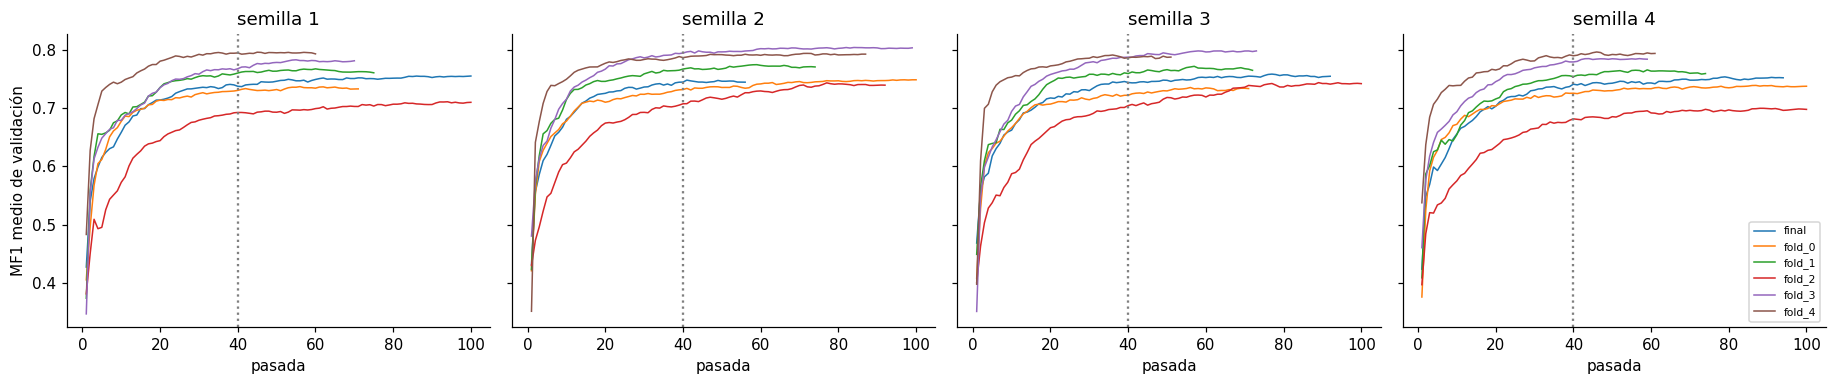

In [16]:
# Curvas de entrenamiento de cada semilla
fig, axes = plt.subplots(1, len(SEMILLAS), figsize=(4.2 * len(SEMILLAS), 3.6), sharey=True, squeeze=False)
for ax, s in zip(axes[0], SEMILLAS):
    for name in NOMBRES:
        lg = pd.read_csv(carpetas(s)[0] / f"{name}_log.csv")
        ax.plot(lg.epoch, lg.score, label=name, lw=1)
    ax.axvline(HP["min_epochs"], ls=":", color="gray")
    ax.set_title(f"semilla {s}")
    ax.set_xlabel("pasada")
axes[0, 0].set_ylabel("MF1 medio de validación")
axes[0, -1].legend(fontsize=7)
plt.tight_layout()
plt.show()

Mejor pasada y puntaje de validación de cada entrenamiento, junto a los de la semilla 42 (`modelo_b_red/2_entrenamiento.ipynb`).

In [17]:
# Mejor pasada y puntaje de validación de cada entrenamiento, con la semilla 42
def resumen_b(semilla, name):
    logs = PROCESADOS_42 / "logs" if semilla == 42 else carpetas(semilla)[0]
    return json.loads((logs / f"{name}_resumen.json").read_text())


TODAS = [42, *SEMILLAS]
pasadas = pd.DataFrame({f"semilla {s}": {n: resumen_b(s, n)["mejor_pasada"] for n in NOMBRES} for s in TODAS})
puntaje = pd.DataFrame({f"semilla {s}": {n: resumen_b(s, n)["puntaje_val"] for n in NOMBRES} for s in TODAS})
display(pasadas)
puntaje.style.format(precision=3)

,semilla 42,semilla 1,semilla 2,semilla 3,semilla 4
final,88,100,41,77,79
fold_0,96,56,100,56,87
fold_1,74,60,59,57,59
fold_2,89,94,77,89,88
fold_3,75,55,84,58,44
fold_4,35,45,72,36,46


,semilla 42,semilla 1,semilla 2,semilla 3,semilla 4
final,0.754,0.756,0.749,0.759,0.754
fold_0,0.747,0.738,0.749,0.736,0.740
fold_1,0.773,0.768,0.775,0.773,0.766
fold_2,0.758,0.711,0.744,0.744,0.700
fold_3,0.802,0.784,0.805,0.799,0.786
fold_4,0.789,0.797,0.795,0.792,0.797


### Por combinación

MF1 de la red sola en cada combinación. **CV:** predicciones fuera de fold de los 62 sujetos de desarrollo. **Test:** los 16 sujetos de test, con el modelo final. Las dos últimas columnas son la media y la desviación estándar de las 5 semillas.

In [18]:
# Funciones para leer las predicciones de una semilla y resumir varias semillas
def load_fold_preds(semilla, name):
    """combinación -> noche -> (y, probabilidades)"""
    preds = PROCESADOS_42 / "predicciones" if semilla == 42 else carpetas(semilla)[1]
    z = np.load(preds / f"{name}.npz")
    out = {}
    for k in z.files:
        if k.startswith(("y__", "pos__")):
            continue
        cfg, n = k.split("__")
        out.setdefault(cfg, {})[n] = (z[f"y__{n}"], z[k])
    return out


def metrics_of(preds):
    y = np.concatenate([y for y, _ in preds.values()])
    p = np.concatenate([p.argmax(1) for _, p in preds.values()])
    return compute_metrics(y, p)


def con_media(tabla):
    """Agrega la media y la desviación estándar entre semillas."""
    return tabla.assign(media=tabla.mean(1), de=tabla.std(1))

In [19]:
# MF1 de la red por combinación y semilla: CV y test
cv, test = {}, {}
for s in TODAS:
    oof = {c: {} for c in CONFIGS}
    for name in [n for n in NOMBRES if n != "final"]:
        for c, d in load_fold_preds(s, name).items():
            oof[c].update(d)
    te = load_fold_preds(s, "final")
    cv[f"semilla {s}"] = {c: metrics_of(oof[c])["mf1"] for c in CONFIGS}
    test[f"semilla {s}"] = {c: metrics_of(te[c])["mf1"] for c in CONFIGS}
cv_b, test_b = con_media(pd.DataFrame(cv)), con_media(pd.DataFrame(test))
print("CV (62 sujetos de desarrollo)")
display(cv_b.style.format(precision=3))
print("test (16 sujetos)")
test_b.style.format(precision=3)

CV (62 sujetos de desarrollo)


,semilla 42,semilla 1,semilla 2,semilla 3,semilla 4,media,de
fpz,0.766,0.756,0.772,0.761,0.756,0.762,0.007
pz,0.737,0.732,0.738,0.735,0.732,0.735,0.003
eeg2,0.783,0.771,0.786,0.779,0.772,0.778,0.006
fpz_eog,0.780,0.772,0.786,0.777,0.772,0.777,0.006
pz_eog,0.770,0.763,0.777,0.768,0.766,0.769,0.005
eeg2_eog,0.790,0.779,0.794,0.787,0.782,0.787,0.006
fpz_emg,0.772,0.763,0.776,0.767,0.763,0.768,0.006
pz_emg,0.740,0.738,0.744,0.739,0.738,0.740,0.002
eeg2_emg,0.784,0.774,0.788,0.781,0.775,0.780,0.006
fpz_eog_emg,0.781,0.773,0.788,0.779,0.775,0.779,0.006


test (16 sujetos)


,semilla 42,semilla 1,semilla 2,semilla 3,semilla 4,media,de
fpz,0.749,0.752,0.749,0.754,0.752,0.751,0.002
pz,0.710,0.713,0.715,0.713,0.717,0.714,0.003
eeg2,0.764,0.765,0.763,0.766,0.767,0.765,0.002
fpz_eog,0.758,0.763,0.759,0.765,0.762,0.762,0.003
pz_eog,0.737,0.739,0.738,0.739,0.742,0.739,0.002
eeg2_eog,0.768,0.767,0.766,0.768,0.770,0.767,0.002
fpz_emg,0.752,0.752,0.749,0.755,0.754,0.752,0.002
pz_emg,0.713,0.715,0.719,0.717,0.719,0.717,0.003
eeg2_emg,0.764,0.760,0.757,0.763,0.765,0.762,0.003
fpz_eog_emg,0.756,0.756,0.758,0.761,0.760,0.758,0.002


## 8. Redes guardadas

Se reconstruye la red final de cada semilla con los hiperparámetros guardados en su `modelo_final.pt` y se cargan sus pesos.

In [ ]:
# Reconstruir la red final de cada semilla con sus hiperparámetros
for s in SEMILLAS:
    ck = torch.load(carpetas(s)[3] / "modelo_final.pt", map_location="cpu", weights_only=False)
    red_final = CnnTransformer(**ck["ARQUITECTURA"])
    red_final.load_state_dict(ck["model_state_dict"])
    assert ck["semilla"] == s and ck["mejor_pasada"] == resumen_b(s, "final")["mejor_pasada"]
    print(f"semilla {s}: red final de la pasada {ck['mejor_pasada']}, puntaje de validación {ck['puntaje_val']:.3f}")

semilla 1: red final de la pasada 100, puntaje de validación 0.756
semilla 2: red final de la pasada 41, puntaje de validación 0.749
semilla 3: red final de la pasada 77, puntaje de validación 0.759
semilla 4: red final de la pasada 79, puntaje de validación 0.754


## 9. Conclusiones

- Los 24 entrenamientos nuevos terminaron y cada uno guardó su red.
- La parada temprana sí depende de la semilla: la mejor pasada de un mismo entrenamiento cambia mucho de una semilla a otra (la del final va de 41 a 100).
- Pero el resultado casi no cambia. En el test, el MF1 de la red varía entre semillas con una desviación estándar de 0.002–0.003 en las 12 combinaciones: solo Fpz-Cz 0.751 ± 0.002 y 4 canales 0.764 ± 0.002.
- En la CV varía algo más (0.002–0.007), porque cada fold depende de un solo entrenamiento y algunos, como el fold 2, cambian bastante con la semilla.
- La semilla 42 no es un caso aparte: en la CV queda entre las más altas y en el test entre las más bajas, siempre a 0.005 o menos de la media.